# Comparación entre Diseños: Muestras Independientes vs. Mediciones Pareadas
## ¿Por qué el diseño determina el análisis estadístico?

Este notebook complementario para la **Sesión 8** ilustra de manera visual, matemática e interactiva la diferencia fundamental entre dos estrategias de diseño experimental y muestreo al comparar dos tratamientos o versiones de software:

1. **Diseño de Muestras Independientes (Grupos No Relacionados):**
   * Cada caso de prueba o usuario se asigna a una sola versión (Baseline **o** Optimized).
   * La variabilidad total incluye tanto el efecto de la versión como la heterogeneidad intrínseca entre sujetos/casos de prueba.
   * Análisis apropiado: **Prueba $t$ de Welch** (`scipy.stats.ttest_ind(..., equal_var=False)`).

2. **Diseño de Mediciones Pareadas (Muestras Dependientes):**
   * Cada caso de prueba o usuario se evalúa bajo **ambas versiones** (Baseline **y** Optimized).
   * Cada unidad actúa como su propio control, eliminando la heterogeneidad base entre casos.
   * Análisis apropiado: **Prueba $t$ pareada** (`scipy.stats.ttest_rel` o prueba de una muestra sobre las diferencias $d_i$).

---

### Objetivos de Aprendizaje:
* Comprender algebraicamente cómo la **correlación intra-par ($\rho > 0$)** reduce drásticamente el error estándar del estimador.
* Visualizar por qué tratar datos pareados como independientes desperdicia potencia estadística (*Type II error inflation*).
* Demostrar que los valores p de ambos diseños no son intercambiables ni comparables en competencia.


In [1]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

# Estilos visuales
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 4.5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
pd.set_option('display.precision', 4)

print("Entorno cargado para la comparación de diseños.")


Entorno cargado para la comparación de diseños.


---

## 1. El Fundamento Matemático: El Poder de la Correlación Intra-Par

Consideremos dos variables $X_1$ (Baseline) y $X_2$ (Optimized). La varianza de la diferencia entre sus medias es:

$$\text{Var}(\bar{X}_1 - \bar{X}_2) = \text{Var}(\bar{X}_1) + \text{Var}(\bar{X}_2) - 2\text{Cov}(\bar{X}_1, \bar{X}_2)$$

Para muestras de tamaño $n$:
$$\text{Var}(\bar{X}_1 - \bar{X}_2) = \frac{\sigma_1^2}{n} + \frac{\sigma_2^2}{n} - 2 \rho \frac{\sigma_1 \sigma_2}{n}$$

Donde $\rho = \text{Corr}(X_1, X_2)$ es el coeficiente de correlación lineal entre las mediciones del mismo caso:

* **Si las muestras son independientes ($\rho = 0$):**
  $$SE_{\text{indep}} = \sqrt{\frac{\sigma_1^2}{n_1} + \frac{\sigma_2^2}{n_2}}$$
  El término de covarianza es nulo. Toda la variación natural entre casos se suma al error estándar.

* **Si las mediciones son pareadas sobre el mismo caso ($\rho > 0$):**
  $$SE_{\text{pareado}} = \sqrt{\frac{\sigma_1^2 + \sigma_2^2 - 2\rho\sigma_1\sigma_2}{n}} = \frac{\sigma_d}{\sqrt{n}}$$
  Cuando los casos tienen diferentes niveles base de dificultad (e.g. unos tardan 100 ms y otros 400 ms), $\rho$ es alta y positiva ($\rho \to 1$).
  **El término $-2\rho\sigma_1\sigma_2$ sustrae la mayor parte del ruido**, reduciendo el error estándar a una fracción del independiente.


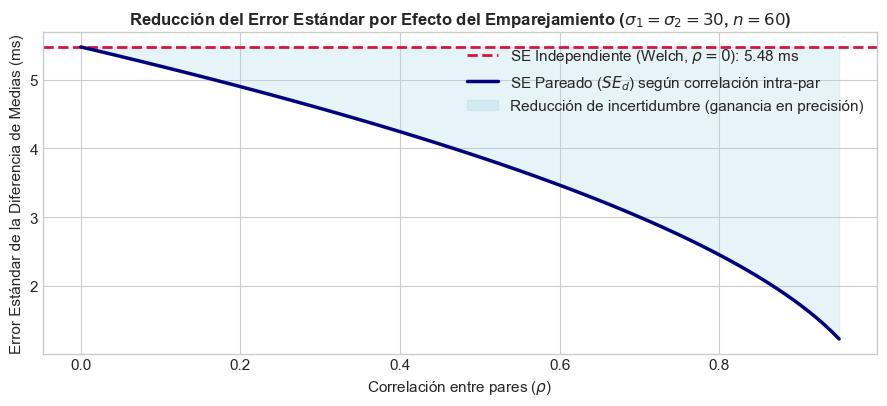

In [2]:
# Simulación: Efecto del coeficiente de correlación (rho) sobre el Error Estándar
sigma1, sigma2 = 30.0, 30.0
n = 60
rhos = np.linspace(0.0, 0.95, 100)

se_independent = np.sqrt((sigma1**2 / n) + (sigma2**2 / n))
se_paired = np.sqrt((sigma1**2 + sigma2**2 - 2 * rhos * sigma1 * sigma2) / n)

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.axhline(se_independent, color='crimson', linestyle='--', lw=2, label=f'SE Independiente (Welch, $\\rho=0$): {se_independent:.2f} ms')
ax.plot(rhos, se_paired, color='navy', lw=2.5, label=r'SE Pareado ($SE_d$) según correlación intra-par')

ax.set_title(r'Reducción del Error Estándar por Efecto del Emparejamiento ($\sigma_1=\sigma_2=30$, $n=60$)')
ax.set_xlabel(r'Correlación entre pares ($\rho$)')
ax.set_ylabel(r'Error Estándar de la Diferencia de Medias (ms)')
ax.fill_between(rhos, se_paired, se_independent, color='lightblue', alpha=0.3, label='Reducción de incertidumbre (ganancia en precisión)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


---

## 2. Experimento Simulado: Análisis de un Benchmark de Rendimiento

Simulemos un escenario real de ingeniería de software con $n = 60$ casos de prueba con **alta heterogeneidad de complejidad** (algunos tests son livianos, otros muy pesados):
* Latencia base de los casos: varía entre $120\text{ ms}$ y $380\text{ ms}$.
* Efecto real de la optimización: reduce la latencia en promedio $15.0\text{ ms}$.
* Ruido operacional aleatorio por corrida: $\sigma_{\text{ruido}} = 8.0\text{ ms}$.

Comparemos:
1. **Análisis correcto respetando el diseño pareado:** $d_i = x_{i, opt} - x_{i, base}$.
2. **Análisis incorrecto ignorando el emparejamiento:** tratando las dos columnas como si vinieran de grupos independientes.


In [3]:
np.random.seed(42)
n_cases = 60

# 1. Dificultad intrínseca de cada caso (fuente dominante de varianza)
dificultad_base = stats.uniform.rvs(loc=120, scale=260, size=n_cases, random_state=42)

# 2. Mediciones observadas bajo cada versión para el MISMO caso
ruido_base = stats.norm.rvs(loc=0, scale=8.0, size=n_cases, random_state=101)
ruido_opt = stats.norm.rvs(loc=0, scale=8.0, size=n_cases, random_state=202)

latencia_base = dificultad_base + ruido_base
latencia_opt = (dificultad_base - 15.0) + ruido_opt

# Diferencias intra-par
diffs = latencia_opt - latencia_base

# Correlación empírica
r_obs = np.corrcoef(latencia_base, latencia_opt)[0, 1]

print(f"Desviación estándar de Baseline:     {np.std(latencia_base, ddof=1):.2f} ms")
print(f"Desviación estándar de Optimized:    {np.std(latencia_opt, ddof=1):.2f} ms")
print(f"Desviación estándar de DIFERENCIAS:  {np.std(diffs, ddof=1):.2f} ms  <-- ¡Notablemente menor!")
print(f"Correlación entre pares (r):         {r_obs:.4f}")


Desviación estándar de Baseline:     80.00 ms
Desviación estándar de Optimized:    78.41 ms
Desviación estándar de DIFERENCIAS:  10.34 ms  <-- ¡Notablemente menor!
Correlación entre pares (r):         0.9917


### 2.1 Contraste Estadístico: ¿Qué ocurre si ignoramos el diseño?

In [4]:
# 1. Análisis CORRECTO: Prueba t Pareada
res_paired = stats.ttest_rel(latencia_opt, latencia_base)
se_p = np.std(diffs, ddof=1) / np.sqrt(n_cases)
ci_p = (np.mean(diffs) - stats.t.ppf(0.975, df=n_cases-1)*se_p,
        np.mean(diffs) + stats.t.ppf(0.975, df=n_cases-1)*se_p)

# 2. Análisis INCORRECTO: Tratar datos pareados con t de Welch (muestras independientes)
res_welch = stats.ttest_ind(latencia_opt, latencia_base, equal_var=False)
se_w = np.sqrt(np.var(latencia_opt, ddof=1)/n_cases + np.var(latencia_base, ddof=1)/n_cases)
ci_w = (np.mean(diffs) - stats.t.ppf(0.975, df=res_welch.df)*se_w,
        np.mean(diffs) + stats.t.ppf(0.975, df=res_welch.df)*se_w)

tabla_comparacion = pd.DataFrame({
    'Diseño y Método Aplicado': [
        'Análisis Pareado (CORRECTO: respeta el diseño)',
        'Análisis Independiente Welch (INCORRECTO: ignora emparejamiento)'
    ],
    'Diferencia media (x̄_diff)': [np.mean(diffs), np.mean(diffs)],
    'Error Estándar (SE)': [se_p, se_w],
    'Estadístico t': [res_paired.statistic, res_welch.statistic],
    'P-valor': [res_paired.pvalue, res_welch.pvalue],
    'IC 95%': [f"[{ci_p[0]:.2f}, {ci_p[1]:.2f}]", f"[{ci_w[0]:.2f}, {ci_w[1]:.2f}]"],
    'Conclusión (α=0.05)': [
        'Rechazar H0 (Evidencia contundente de mejora)',
        'No rechazar H0 (¡Falso negativo / Error Tipo II!)'
    ]
})
tabla_comparacion


,Diseño y Método Aplicado,Diferencia media (x̄_diff),Error Estándar (SE),Estadístico t,P-valor,IC 95%,Conclusión (α=0.05)
0,Análisis Pareado (CORRECTO: respeta el diseño),-17.4199,1.3351,-13.0481,4.8723e-19,"[-20.09, -14.75]",Rechazar H0 (Evidencia contundente de mejora)
1,Análisis Independiente Welch (INCORRECTO: igno...,-17.4199,14.4612,-1.2046,2.3077e-01,"[-46.06, 11.22]",No rechazar H0 (¡Falso negativo / Error Tipo II!)


---

## 3. Diagnósticos Gráficos: Visualizando la Estructura de los Datos

Las siguientes gráficas permiten diagnosticar visualmente si el emparejamiento es efectivo y por qué el análisis marginal falla:
1. **Gráfico de Dispersión de Pares ($y$ vs. $x$):** la cercanía de los puntos a una recta paralela a la identidad evidencia la correlación intra-par.
2. **Distribución Marginal vs. Distribución de Diferencias:** muestra cómo la varianza se contrae al calcular $d_i$.


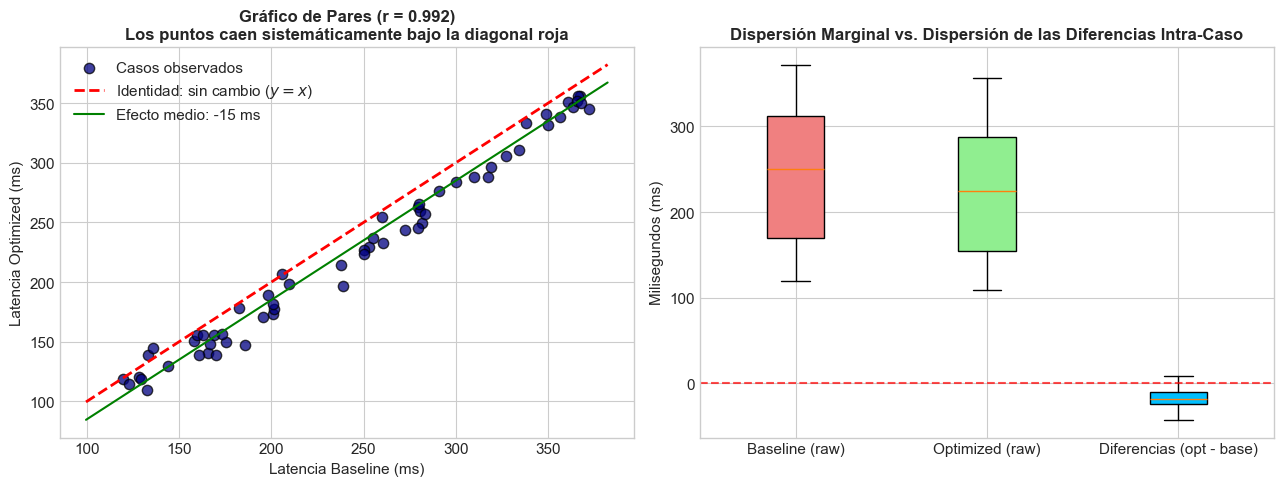

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico 1: Pares y línea de identidad
ax1.scatter(latencia_base, latencia_opt, color='navy', edgecolors='k', alpha=0.75, s=55, label='Casos observados')
min_val = min(min(latencia_base), min(latencia_opt)) - 10
max_val = max(max(latencia_base), max(latencia_opt)) + 10
ax1.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Identidad: sin cambio ($y = x$)')
ax1.plot([min_val, max_val], [min_val - 15, max_val - 15], 'g-', lw=1.5, label='Efecto medio: -15 ms')
ax1.set_xlabel('Latencia Baseline (ms)')
ax1.set_ylabel('Latencia Optimized (ms)')
ax1.set_title(f'Gráfico de Pares (r = {r_obs:.3f})\nLos puntos caen sistemáticamente bajo la diagonal roja')
ax1.legend()

# Gráfico 2: Comparación de variabilidad (marginales vs diferencia)
box_data = [latencia_base, latencia_opt, diffs]
bp = ax2.boxplot(box_data, patch_artist=True, tick_labels=['Baseline (raw)', 'Optimized (raw)', 'Diferencias (opt - base)'])
colors = ['lightcoral', 'lightgreen', 'deepskyblue']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
ax2.axhline(0, color='red', linestyle='--', alpha=0.7)
ax2.set_ylabel('Milisegundos (ms)')
ax2.set_title('Dispersión Marginal vs. Dispersión de las Diferencias Intra-Caso')

plt.tight_layout()
plt.show()


---

## 4. Curvas de Potencia Estadística: ¿Cuánta ventaja aporta el diseño pareado?

A continuación simulamos la **potencia estadística** ($1 - \beta$) para detectar una reducción de $10\text{ ms}$ con $n = 30$ casos de prueba conforme varía la correlación intra-par $\rho$ entre 0.0 y 0.90.


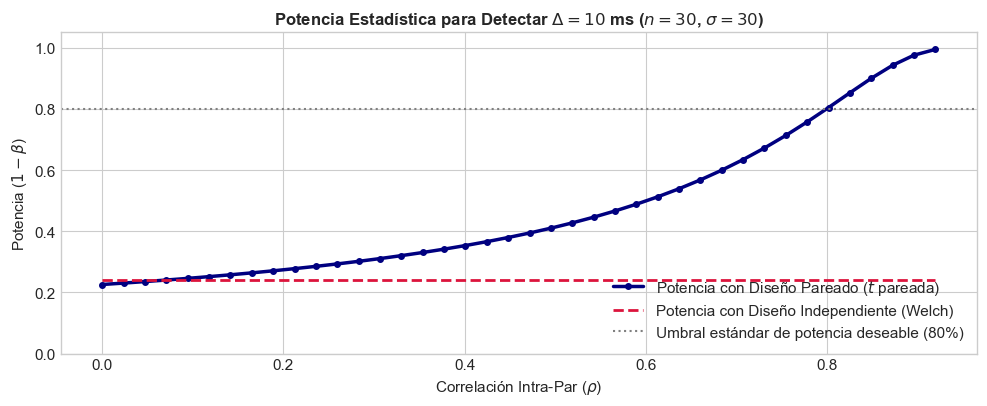

In [6]:
# Simulación analítica de potencia
delta_shift = 10.0
sig = 30.0
n_sim = 30
alpha_sim = 0.05

grid_rho = np.linspace(0.0, 0.92, 40)
power_paired = []
power_welch = []

for r in grid_rho:
    # Error estándar pareado
    se_pair = np.sqrt(2 * (sig**2) * (1 - r) / n_sim)
    ncp_pair = delta_shift / se_pair
    t_crit_p = stats.t.ppf(1 - alpha_sim / 2, df=n_sim - 1)
    # Potencia bilateral aproximada
    pwr_p = stats.norm.sf(t_crit_p - ncp_pair) + stats.norm.cdf(-t_crit_p - ncp_pair)
    power_paired.append(pwr_p)
    
    # Error estándar independiente
    se_indep = np.sqrt(2 * (sig**2) / n_sim)
    ncp_indep = delta_shift / se_indep
    t_crit_w = stats.t.ppf(1 - alpha_sim / 2, df=2 * n_sim - 2)
    pwr_w = stats.norm.sf(t_crit_w - ncp_indep) + stats.norm.cdf(-t_crit_w - ncp_indep)
    power_welch.append(pwr_w)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(grid_rho, power_paired, 'navy', lw=2.5, marker='o', markersize=4, label='Potencia con Diseño Pareado ($t$ pareada)')
ax.plot(grid_rho, power_welch, 'crimson', lw=2, linestyle='--', label='Potencia con Diseño Independiente (Welch)')

ax.axhline(0.80, color='gray', linestyle=':', label='Umbral estándar de potencia deseable (80%)')
ax.set_title(r'Potencia Estadística para Detectar $\Delta = 10$ ms ($n = 30$, $\sigma = 30$)')
ax.set_xlabel(r'Correlación Intra-Par ($\rho$)')
ax.set_ylabel(r'Potencia ($1 - \beta$)')
ax.set_ylim(0, 1.05)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


---

## 5. Conclusiones y Reglas de Oro para la Práctica Profesional

1. **El diseño precede al código:**
   * La estructura de los datos (si hay o no identificación única del caso evaluado en ambas condiciones) dicta si se aplica una prueba pareada o de grupos independientes.
   * **Nunca elija el método mirando cuál p-valor es más pequeño**; eso constituye *data dredging* o *p-hacking*.

2. **Por qué emparejar cuando sea posible:**
   * Cuando los casos de prueba, cargas de trabajo o usuarios presentan una gran variabilidad natural previa, emparejar elimina esa variabilidad del denominador del estadístico, multiplicando la potencia estadística sin necesidad de recolectar más muestras.

3. **Cuándo NO emparejar:**
   * Si la primera prueba produce efectos residuales sobre la segunda (efectos de orden, calentamiento de caché, contención de disco no reseteada) y no se puede aleatorizar el orden, las mediciones no serán intercambiables.
   * Si las unidades de prueba son inherentemente independientes (e.g. dos grupos aleatorios de clientes en pruebas A/B), forzar un emparejamiento artificial destruye la validez del análisis.
